<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7: Perceptron and Forward Propagation

**Category**: CO2 – Neural Networks and CNNs  
**Objective**: Build binary perceptron from first principles, evaluate on logic gates and visualize linear decision boundaries.


### Task 1: Single Perceptron for Binary Logic Gates (AND / OR)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

class BinaryPerceptron:
    def __init__(self, n_features, lr=0.1, epochs=20):
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.lr = lr
        self.epochs = epochs

    def step_activate(self, z):
        return np.where(z >= 0, 1, 0)

    def fit(self, X, y):
        for ep in range(self.epochs):
            for xi, target in zip(X, y):
                pred = self.step_activate(np.dot(xi, self.weights) + self.bias)
                err = target - pred
                self.weights += self.lr * err * xi
                self.bias += self.lr * err

    def predict(self, X):
        return self.step_activate(np.dot(X, self.weights) + self.bias)

# Logic datasets
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or = np.array([0, 1, 1, 1])

and_percept = BinaryPerceptron(2)
and_percept.fit(X_logic, y_and)
print("AND Gate Predictions:", and_percept.predict(X_logic))
print("AND Learned Weights:", np.round(and_percept.weights, 3), "Bias:", round(and_percept.bias, 3))

or_percept = BinaryPerceptron(2)
or_percept.fit(X_logic, y_or)
print("OR Gate Predictions:", or_percept.predict(X_logic))
print("OR Learned Weights:", np.round(or_percept.weights, 3), "Bias:", round(or_percept.bias, 3))


AND Gate Predictions: [0 0 0 1]
AND Learned Weights: [0.2 0.1] Bias: -0.2
OR Gate Predictions: [0 1 1 1]
OR Learned Weights: [0.1 0.1] Bias: -0.1


### Task 2: Train Perceptron on Linearly Separable Synthetic Data


In [2]:
from sklearn.datasets import make_blobs

X_synth, y_synth = make_blobs(n_samples=120, centers=2, n_features=2, random_state=42, cluster_std=1.2)
clf_percept = BinaryPerceptron(2, lr=0.05, epochs=30)
clf_percept.fit(X_synth, y_synth)

accuracy = np.mean(clf_percept.predict(X_synth) == y_synth) * 100
print(f"Perceptron Training Accuracy on 2D Clusters: {accuracy:.2f}%")


Perceptron Training Accuracy on 2D Clusters: 100.00%


### Task 3: Visualize Perceptron Decision Boundary


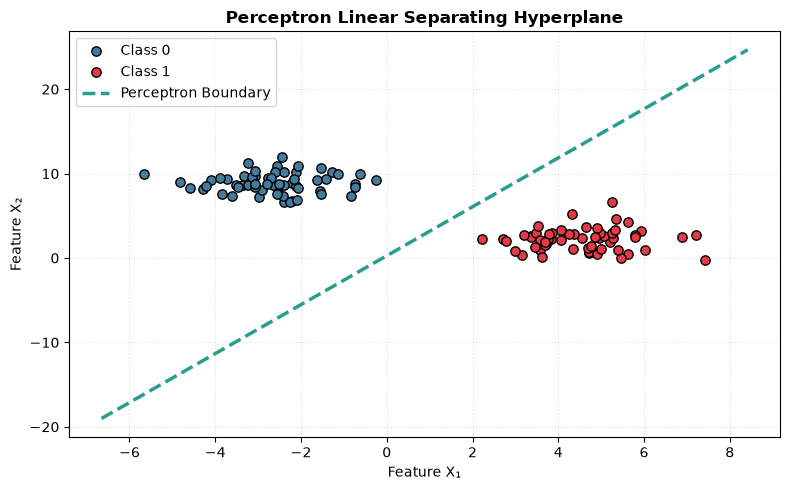

In [3]:
x_span = np.linspace(X_synth[:, 0].min() - 1, X_synth[:, 0].max() + 1, 200)
# w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
w1, w2 = clf_percept.weights
b_val = clf_percept.bias
boundary_line = -(w1 * x_span + b_val) / w2

plt.figure(figsize=(8, 5))
plt.scatter(X_synth[y_synth == 0, 0], X_synth[y_synth == 0, 1], color='#457b9d', label='Class 0', edgecolors='k', s=45)
plt.scatter(X_synth[y_synth == 1, 0], X_synth[y_synth == 1, 1], color='#e63946', label='Class 1', edgecolors='k', s=45)
plt.plot(x_span, boundary_line, color='#2a9d8f', lw=2.5, linestyle='--', label='Perceptron Boundary')
plt.title("Perceptron Linear Separating Hyperplane", fontweight='bold')
plt.xlabel("Feature X₁")
plt.ylabel("Feature X₂")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()
